# CUBIT Model

This notebook explores the possibility of integrating a frequency dependent capacitor to produce a qubit that employs a non-linear capacitor (coined CUBIT in [insert reference]). 

## Nanocapacitor Data from [insert ref]

First, the data from Fig. 7 [insert reference] was obtained from WebPlotDigitizer. In the next block, I plot the datasets `S2_3-4` and `S2_2-3` and compare them to Fig. 7 [insert reference]. The output shows a side-by-side comparison of the data from [insert reference] with the data from the WPD.  

In [2]:
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook

import numpy as np
import pandas as pd

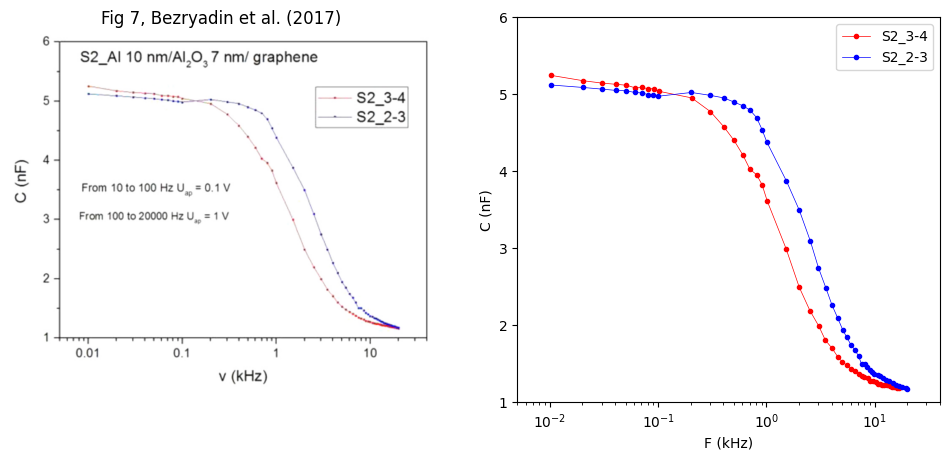

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Read in the datasets
s2_34 = pd.read_csv("data/S2_3-4.csv", header=None, names=["f_kHz", "C_nF"])
s2_23 = pd.read_csv("data/S2_2-3.csv", header=None, names=["f_kHz", "C_nF"])

x_34, y_34 = s2_34["f_kHz"], s2_34["C_nF"]
x_23, y_23 = s2_23["f_kHz"], s2_23["C_nF"]

# Image of Fig 7 from the paper
img = Image.open("figures/S2-3_4_2-3.jpg")

# Image on the left, data on the right
fig, (ax_img, ax_data) = plt.subplots(1, 2, figsize=(12, 5))

ax_img.imshow(img)
ax_img.axis("off")
ax_img.set_title("Fig 7, Bezryadin et al. (2017)")

ax_data.plot(x_34, y_34, "o-", linewidth=0.5, label="S2_3-4", color="red", ms=3)
ax_data.plot(x_23, y_23, "o-", linewidth=0.5, label="S2_2-3", color="blue", ms=3)

ax_data.set_xscale("log")
ax_data.set(xlim=(0.005, 40), ylim=(1, 6))
ax_data.set(xlabel="F (kHz)", ylabel="C (nF)")
ax_data.legend()

plt.show()

The capacitor used in the experiment can be modeled as a Debye capacitor. We can curve fit this model to get the original parameters of this experiment: $C_\infty$, the baseline/instantaneous capacitance, $\Delta C$, the slow capacitance, and $\tau$, the relaxation time constant. 

Run the block below to get curve fitted values that used results from both datasets `S2_2-3` and `S2_3-4`.

In [47]:
from scipy.optimize import curve_fit
from models import DebyeCapacitor

# define the model function

def debye_for_curve_fit(f, c_inf, del_c, log_tau):
    result = DebyeCapacitor(c_inf, del_c, 10 ** log_tau).computeCapacitance(f)
    return result

f_Hz_comb = np.concatenate([x_23 * 1000, x_34 * 1000])
y_nF_comb = np.concatenate([y_23, y_34])

popt, pcov = curve_fit(debye_for_curve_fit, f_Hz_comb, y_nF_comb)

c_inf, del_c, log_tau = popt
sig_c_inf, sig_del_c, sig_log_tau = np.sqrt(np.diag(pcov))

tau = 10 ** log_tau                        # seconds
sig_tau = tau * np.log(10) * sig_log_tau   # propagate the log10 error

print("Debye Fit")
print("--------------------")
print(f"C_inf : {c_inf:.3f} ± {sig_c_inf:.3f} nF")
print(f"del_C : {del_c:.3f} ± {sig_del_c:.3f} nF")
print(f"tau   : {tau * 1e6:.1f} ± {sig_tau * 1e6:.1f} µs")

Debye Fit
--------------------
C_inf : 1.207 ± 0.040 nF
del_C : 3.812 ± 0.053 nF
tau   : 85.5 ± 3.7 µs


We were able to obtain values and uncertainties for the respective parameters. To check that our result matches up, we can plot curves using our fitted values against the original data.

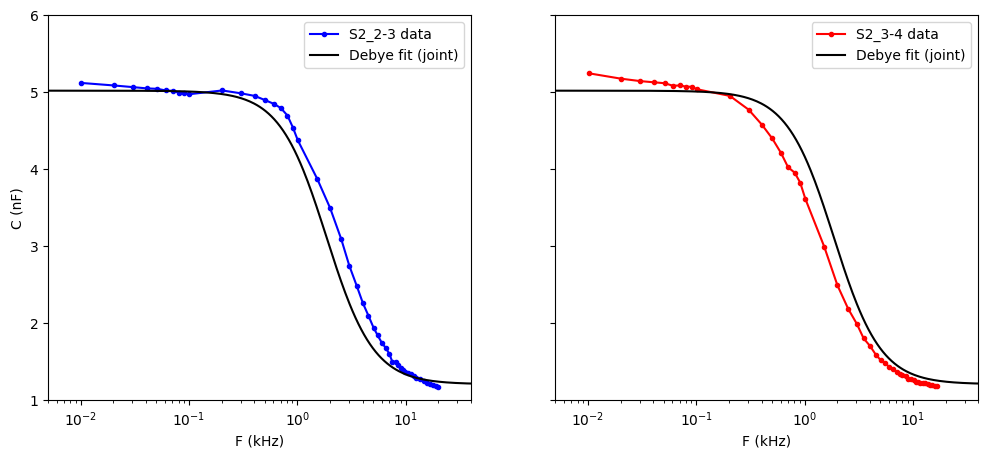

In [54]:
f_grid = np.logspace(-2.3, 1.7, 300)    # kHz
y_fit = DebyeCapacitor(c_inf, del_c, tau).computeCapacitance(f_grid * 1000)

fig, (ax_23, ax_34) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax_23.plot(x_23, y_23, "o-", ms=3, color="blue", label="S2_2-3 data")
ax_23.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

ax_34.plot(x_34, y_34, "o-", ms=3, color="red", label="S2_3-4 data")
ax_34.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

for ax in (ax_23, ax_34):
    ax.set_xscale("log")
    ax.set(xlim=(0.005, 40), ylim=(1, 6), xlabel="F (kHz)")
    ax.legend()
ax_23.set_ylabel("C (nF)")

plt.show()